# Importing Libraries

In [ ]:
# @title
# Library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Plot style setup with error handling
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    # Fallback for older or newer versions
    try:
        plt.style.use('seaborn-darkgrid')
    except:
        plt.style.use('default')

# Consolidated matplotlib settings
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 100,
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9
})

# pandas settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Loading the Data

In [ ]:
import os

# Local data folder (same directory as this notebook)
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

In [ ]:
data_set = pd.read_csv(os.path.join(DATA_DIR, 'data_set.csv'), encoding='latin1',sep=",")

# Exploratory Analysis

In [ ]:
print(f"\nShape: {data_set.shape}")
print(f"Columns: {list(data_set.columns)}")
print(f"\nFirst rows:")
display(data_set.head())

# Defining numeric variables for the analysis

features_in = [col for col in data_set.columns if col.startswith("IN_")]
features_qt = [col for col in data_set.columns if col.startswith("QT_")]
new_features = [
    "MAT_MED_POR_TURMA",
    "MAT_MED_POR_SALA",
    "PROP_SALAS_CLIMATIZADAS",
    "DOC_MED_POR_TURMA_MED",
    "MAT_MED_POR_DOC_MED"
]

all_features = features_in + features_qt + new_features

total_rows = len(data_set)

# number of unique schools
num_unique_schools = data_set["CO_ESCOLA"].nunique()

print(f"Total rows: {total_rows}")
print(f"Number of unique schools: {num_unique_schools}")



Shape: (25179, 96)
Colunas: ['CO_ESCOLA', 'NU_SEQUENCIAL', 'NO_REGIAO', 'SG_UF', 'NO_MUNICIPIO', 'CO_ENTIDADE', 'TP_DEPENDENCIA', 'TP_CATEGORIA_ESCOLA_PRIVADA', 'TP_LOCALIZACAO', 'IN_PREDIO_COMPARTILHADO', 'IN_AREA_VERDE', 'IN_AUDITORIO', 'IN_BANHEIRO', 'IN_BIBLIOTECA', 'IN_DORMITORIO_ALUNO', 'IN_DORMITORIO_PROFESSOR', 'IN_LABORATORIO_CIENCIAS', 'IN_LABORATORIO_INFORMATICA', 'IN_PATIO_COBERTO', 'IN_PATIO_DESCOBERTO', 'IN_PISCINA', 'IN_QUADRA_ESPORTES', 'IN_REFEITORIO', 'IN_SALA_ATELIE_ARTES', 'IN_SALA_MUSICA_CORAL', 'IN_SALA_ESTUDIO_DANCA', 'IN_SALA_MULTIUSO', 'IN_SALA_ESTUDIO_GRAVACAO', 'IN_SALA_OFICINAS_EDUC_PROF', 'IN_SALA_LEITURA', 'IN_SALA_PROFESSOR', 'IN_SALA_REPOUSO_ALUNO', 'IN_SECRETARIA', 'QT_SALAS_UTILIZADAS', 'QT_SALAS_UTILIZA_CLIMATIZADAS', 'IN_COMPUTADOR', 'IN_EQUIP_IMPRESSORA', 'IN_EQUIP_SOM', 'IN_EQUIP_TV', 'IN_EQUIP_LOUSA_DIGITAL', 'IN_EQUIP_MULTIMIDIA', 'IN_DESKTOP_ALUNO', 'IN_COMP_PORTATIL_ALUNO', 'IN_TABLET_ALUNO', 'IN_INTERNET', 'IN_INTERNET_ALUNOS', 'IN_PROF_BIBLI

,CO_ESCOLA,NU_SEQUENCIAL,NO_REGIAO,SG_UF,NO_MUNICIPIO,CO_ENTIDADE,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PATIO_COBERTO,IN_PATIO_DESCOBERTO,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_ATELIE_ARTES,IN_SALA_MUSICA_CORAL,IN_SALA_ESTUDIO_DANCA,IN_SALA_MULTIUSO,IN_SALA_ESTUDIO_GRAVACAO,IN_SALA_OFICINAS_EDUC_PROF,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,IN_SECRETARIA,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_IMPRESSORA,IN_EQUIP_SOM,IN_EQUIP_TV,IN_EQUIP_LOUSA_DIGITAL,IN_EQUIP_MULTIMIDIA,IN_DESKTOP_ALUNO,IN_COMP_PORTATIL_ALUNO,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_ALIMENTACAO,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,IN_EJA,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_AGUA,IN_ENERGIA,IN_ESGOTO,IN_TRATAMENTO_LIXO,IN_ACESSIBILIDADE,IN_RESERVAA,IN_MATERIAL_PED,VINCULO_PUBLICO,VINCULO_PRIVADO,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,PRESENCA_COMPLETA
0,11000058,1872447,Norte,RO,Porto Velho,11000058,4,1.0,1,0.0,0,0,1,1,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,1,0,1,38,38,1,1,1,1,0,1,1,0,0,1,1,1,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,353,28,8,0,0,1,1,1,0,1,NaN,1,<NA><NA><NA><NA>,1000000,1000000,44.12,9.29,1.0,12.61,3.50,0.978495,0.978495,0.978495,0.978495,0.978495
1,11000198,2902420,Norte,RO,Porto Velho,11000198,4,1.0,1,1.0,0,1,1,1,0,0,1,1,1,1,1,1,0,0,0,1,0,0,0,1,1,1,1,44,44,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,188,26,6,0,0,1,1,1,1,1,NaN,1,<NA><NA><NA><NA>,1000000,1000001,31.33,4.27,1.0,7.23,4.33,0.903846,0.923077,0.923077,0.903846,0.903846
2,11000252,3568131,Norte,RO,Porto Velho,11000252,4,1.0,1,0.0,0,1,1,1,0,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,1,25,25,1,1,1,1,0,1,0,0,1,1,1,1,0,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,105,22,5,0,0,1,1,1,1,1,NaN,1,<NA><NA><NA><NA>,1000000,1000000,21.00,4.20,1.0,4.77,4.40,0.944444,0.944444,0.944444,0.944444,0.944444
3,11000260,341779,Norte,RO,Porto Velho,11000260,2,NaN,1,0.0,1,1,1,1,0,0,1,0,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,33,33,1,1,0,1,1,1,0,0,1,1,1,1,0,0,0,0,1,1,1,1,0,1,1,0,1,1,1,0,0,1,1,0,0,0,0,0,411,27,16,0,0,1,1,1,0,1,1.0,1,1100,<NA><NA><NA><NA><NA><NA><NA>,1000000,25.69,12.45,1.0,15.22,1.69,0.934579,0.934579,0.934579,0.934579,0.925234
4,11000317,3993811,Norte,RO,Porto Velho,11000317,2,NaN,1,0.0,0,1,1,1,0,0,1,1,1,0,0,1,1,0,0,0,1,0,0,0,1,0,1,17,17,1,1,0,1,1,1,1,1,0,1,1,1,0,0,0,0,0,1,1,1,0,1,1,0,1,0,1,0,1,1,1,1,0,0,1,180,192,20,6,0,0,1,1,1,0,1,NaN,1,1000,<NA><NA><NA><NA><NA><NA><NA>,1000000,32.00,11.29,1.0,9.60,3.33,0.333333,0.458333,0.458333,0.333333,0.333333


Total de linhas: 25179
Número de escolas únicas: 25179


In [ ]:

low = (data_set["PRESENCA_COMPLETA"] < 0.70).sum()        # mean below 70%
medium = ((data_set["PRESENCA_COMPLETA"] >= 0.70) & (data_set["PRESENCA_COMPLETA"] <= 0.90)).sum()  # 70% to 90%
high = (data_set["PRESENCA_COMPLETA"] > 0.90).sum()        # mean above 90%

total_schools = len(data_set)
percent_low = (low / total_schools) * 100
percent_medium = (medium / total_schools) * 100
percent_high = (high / total_schools) * 100

print(f"{percent_low:.2f}% of schools have LOW mean attendance")
print(f"{percent_medium:.2f}% of schools have MEDIUM mean attendance")
print(f"{percent_high:.2f}% of schools have HIGH mean attendance")



32.97% das escolas têm média de presença BAIXA
38.33% das escolas têm média de presença MEDIA
28.70% das escolas têm média de presença ALTA


In [ ]:
# @title
print("🔍 DATA QUALITY")
print("=" * 50)

# Missing values
missing = data_set.isnull().sum()
print(f"\n❌ Missing values:")
if missing.sum() == 0:
    print("  ✅ No missing values found!")
else:
    print(missing[missing > 0])

# Duplicates
duplicates = data_set.duplicated().sum()
print(f"\n🔄 Duplicate rows: {duplicates}")
if duplicates > 0:
    print(f"  ⚠️ {duplicates} duplicate rows found")


🔍 QUALIDADE DOS DADOS

❌ Valores ausentes:
TP_CATEGORIA_ESCOLA_PRIVADA    18438
IN_PREDIO_COMPARTILHADO          113
IN_RESERVAA                    22547
MAT_MED_POR_TURMA                401
MAT_MED_POR_DOC_MED              401
DOC_MED_POR_TURMA_MED            401
dtype: int64

🔄 Linhas duplicadas0


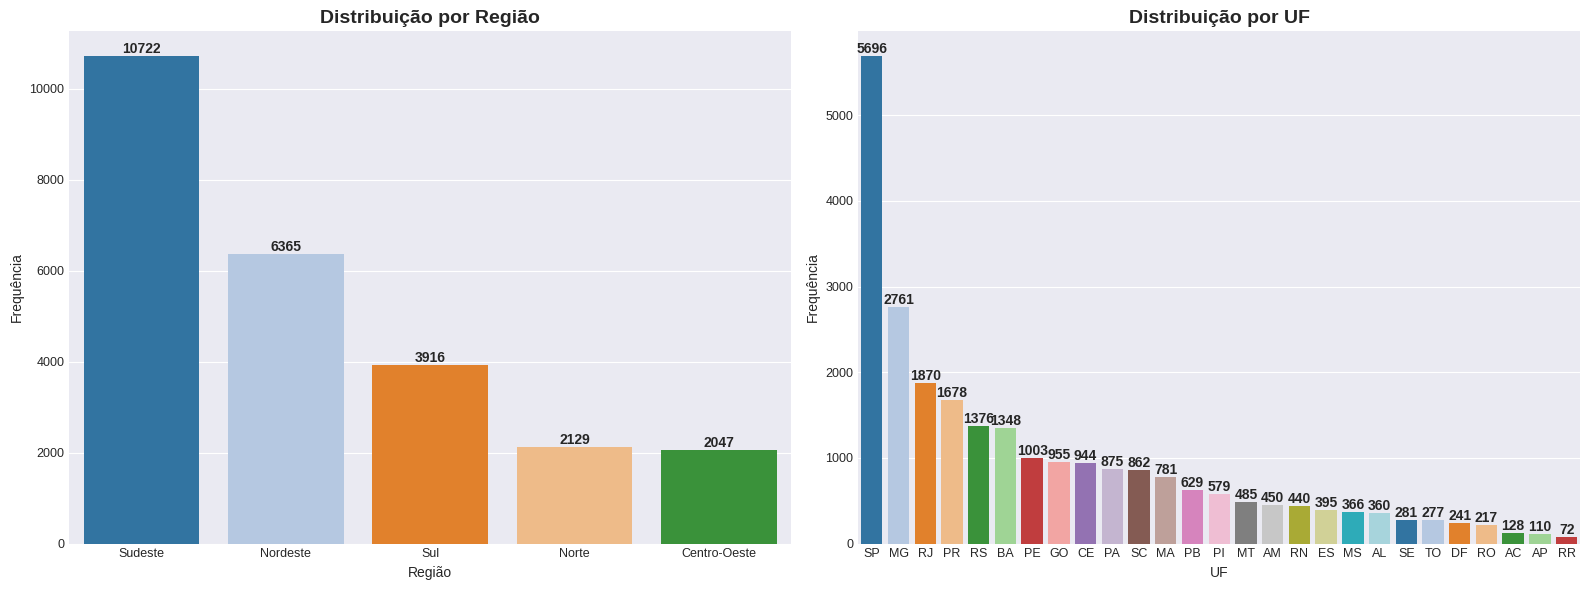

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 6))  # wider figure for two columns

# Chart 1: Region
plt.subplot(1, 2, 1)
ax1 = sns.countplot(
    x="NO_REGIAO",
    data=data_set,
    order=data_set["NO_REGIAO"].value_counts().index,
    palette="tab20"
)
plt.title("Distribution by Region", fontsize=14, weight="bold")
plt.xlabel("Region")
plt.ylabel("Frequency")

# Label the bars with integer values
for p in ax1.patches:
    height = int(p.get_height())
    ax1.annotate(f'{height}',
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

# Chart 2: State (UF)
plt.subplot(1, 2, 2)
ax2 = sns.countplot(
    x="SG_UF",
    data=data_set,
    order=data_set["SG_UF"].value_counts().index,
    palette="tab20"
)
plt.title("Distribution by State (UF)", fontsize=14, weight="bold")
plt.xlabel("State (UF)")
plt.ylabel("Frequency")

# Label the bars with integer values
for p in ax2.patches:
    height = int(p.get_height())
    ax2.annotate(f'{height}',
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

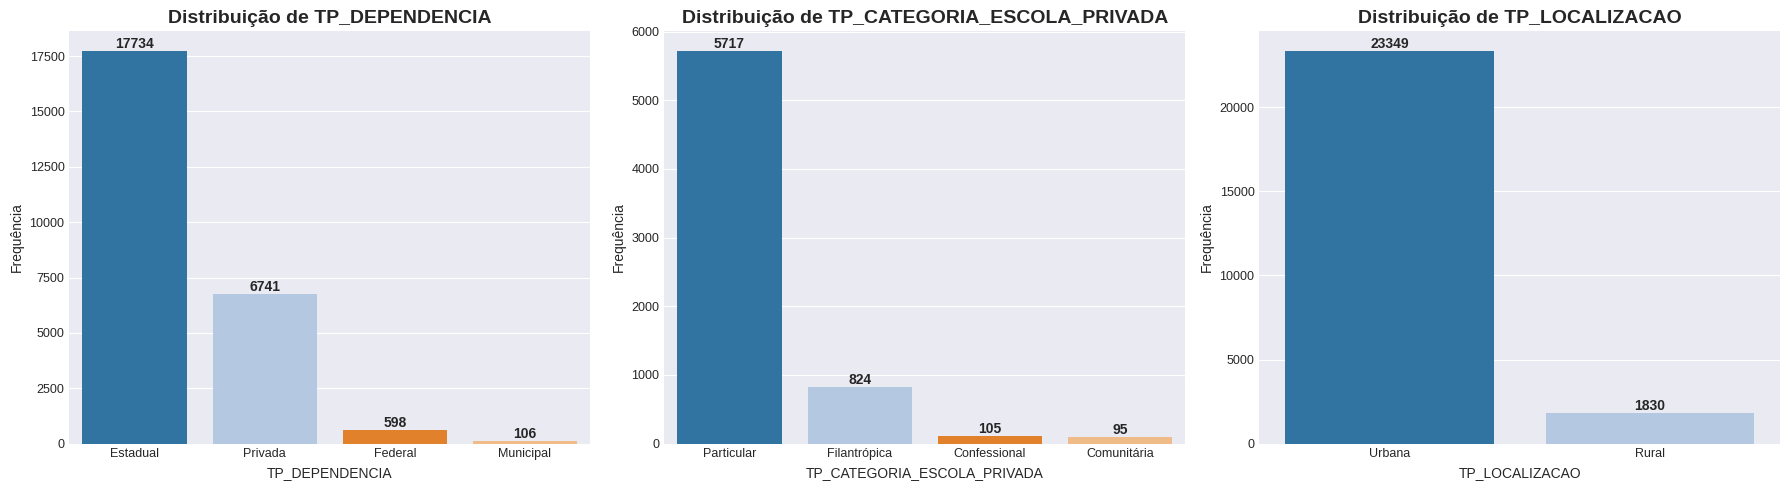

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# mapping dictionaries
dependency_map = {
    1: "Federal",
    2: "State",
    3: "Municipal",
    4: "Private"
}

private_category_map = {
    1: "Particular",
    2: "Community",
    3: "Confessional",
    4: "Philanthropic"
}

location_map = {
    1: "Urban",
    2: "Rural"
}

# apply the mappings
data_plot = data_set.copy()
data_plot["TP_DEPENDENCIA"] = data_plot["TP_DEPENDENCIA"].map(dependency_map)
data_plot["TP_CATEGORIA_ESCOLA_PRIVADA"] = data_plot["TP_CATEGORIA_ESCOLA_PRIVADA"].map(private_category_map)
data_plot["TP_LOCALIZACAO"] = data_plot["TP_LOCALIZACAO"].map(location_map)

# list of the already-converted categorical columns
categorical_cols = [
    "TP_DEPENDENCIA",
    "TP_CATEGORIA_ESCOLA_PRIVADA",
    "TP_LOCALIZACAO"
]

# plot
plt.figure(figsize=(18, 5))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(1, 3, i)
    ax = sns.countplot(
        x=col,
        data=data_plot,
        order=data_plot[col].value_counts().index,
        palette="tab20"
    )
    plt.title(f'Distribution of {col}', fontsize=14, weight='bold')
    plt.xlabel(col)
    plt.ylabel("Frequency")

    # Label the bars with integer values
    for p in ax.patches:
        height = int(p.get_height())
        ax.annotate(f'{height}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
count_df = pd.DataFrame(columns=['Feature', '0', '1'])

results = []

for col in features_in:
    counts = data_set[col].value_counts()  # count the unique values
    results.append({
        'Feature': col,
        '0': counts.get(0, 0),   # or counts.get('0',0) if the values are strings
        '1': counts.get(1, 0)    # or counts.get('1',0) if the values are strings
    })

# Build the final DataFrame in one go
count_df = pd.DataFrame(results)

count_df = count_df.sort_values(by='1', ascending=False).reset_index(drop=True)
display(count_df)


,Feature,0,1
0,IN_ENERGIA,14,25165
1,IN_AGUA,58,25121
2,IN_ESGOTO,117,25062
3,IN_BANHEIRO,167,25012
4,IN_COMPUTADOR,419,24760
5,IN_INTERNET,486,24693
6,IN_DIURNO,529,24650
7,IN_SECRETARIA,1165,24014
8,IN_SALA_PROFESSOR,1248,23931
9,IN_MATERIAL_PED,1476,23703


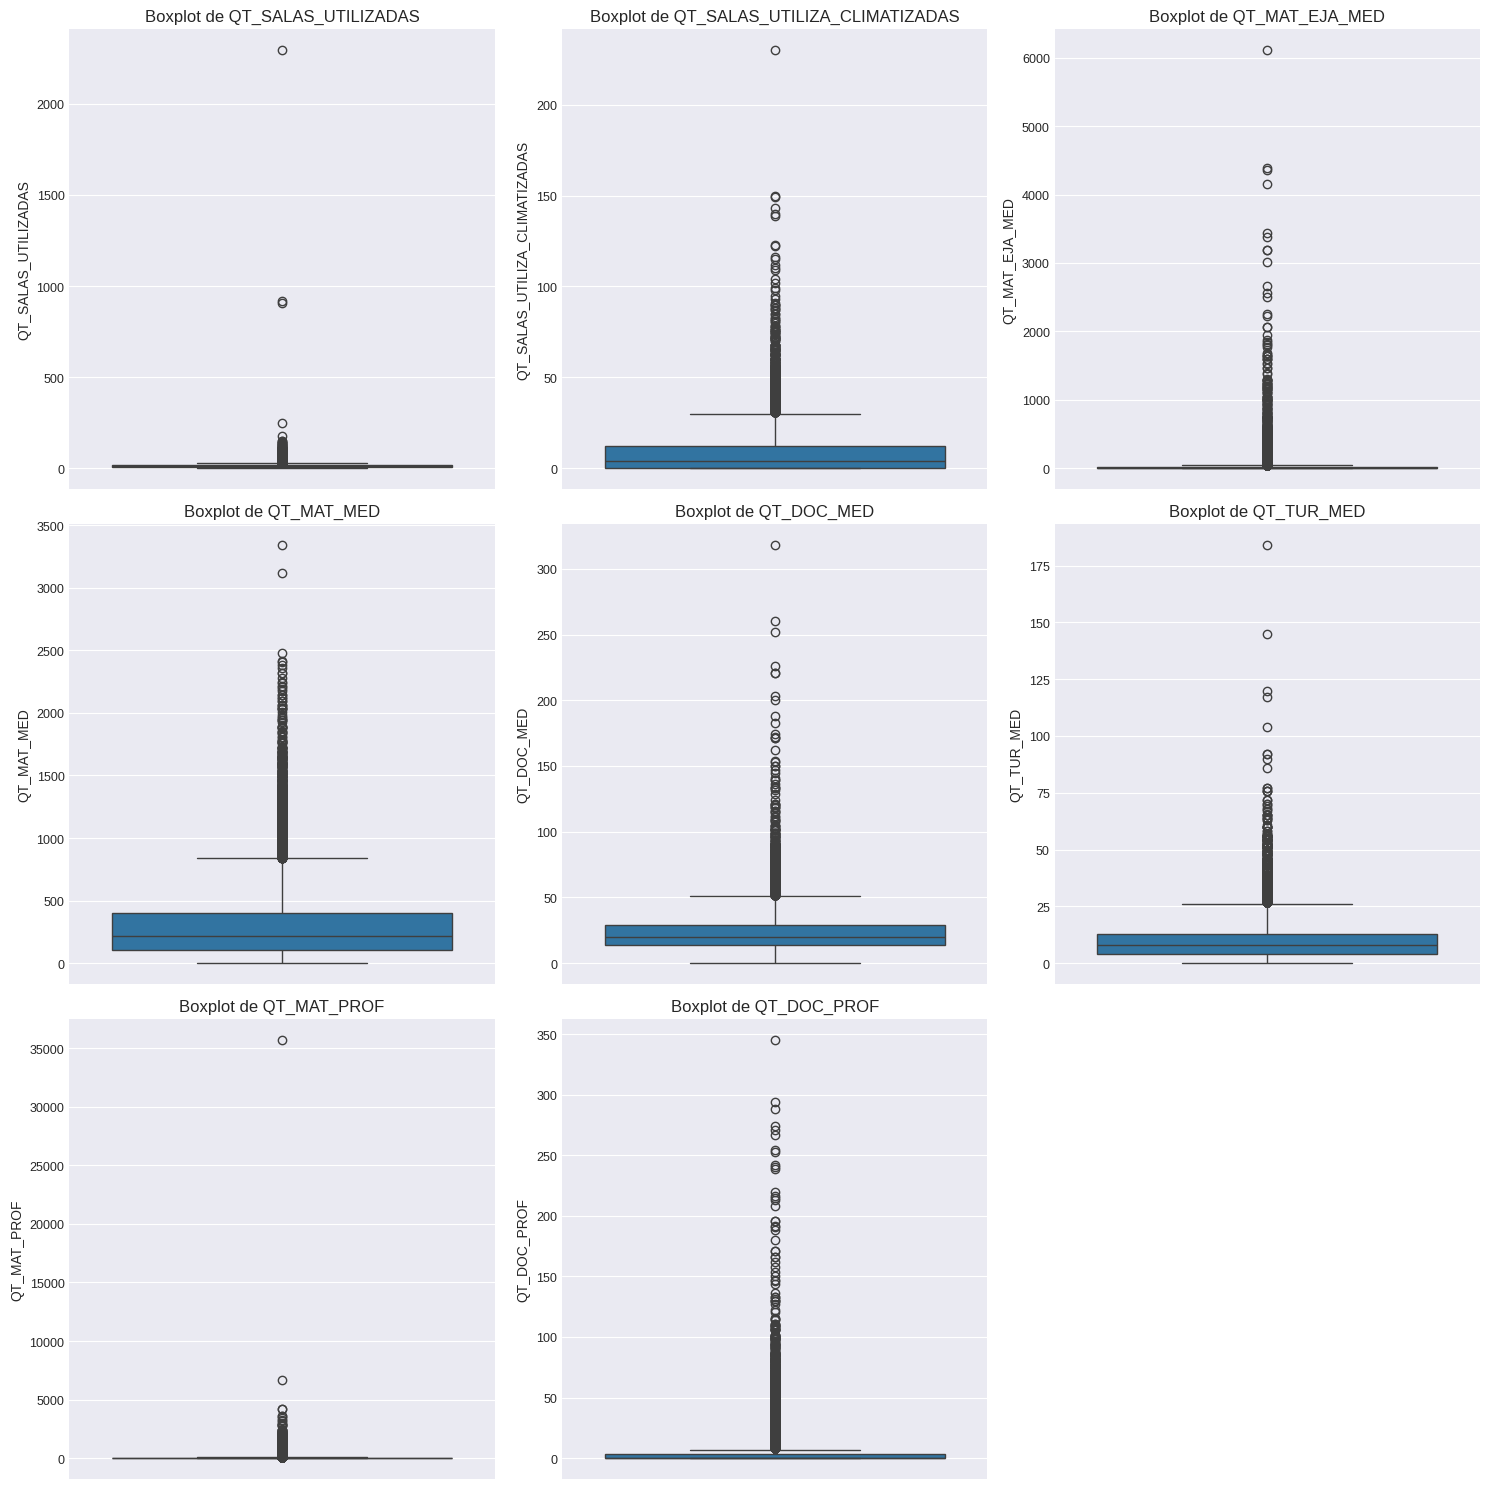

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 15))
for i, col in enumerate(features_qt, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(
        y=data_set[col],
        palette="tab20"
    )
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()


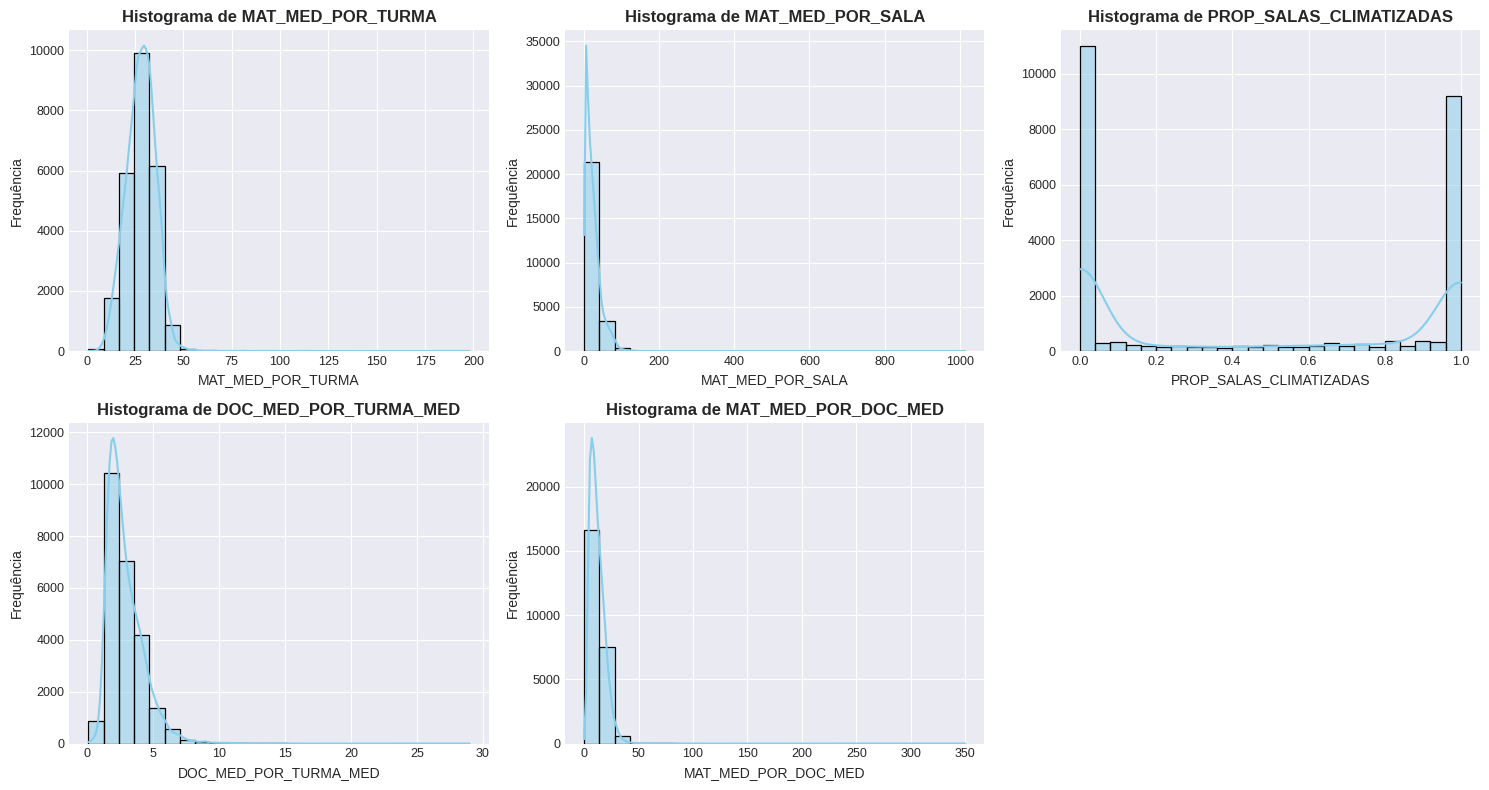

In [ ]:
# How many columns we will plot
n = len(new_features)
n_cols = 3  # number of columns in the grid
n_rows = (n + n_cols - 1) // n_cols  # compute the number of rows needed

plt.figure(figsize=(5 * n_cols, 4 * n_rows))

for i, col in enumerate(new_features, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(
        data_set[col],
        bins=25,
        kde=True,
        color="skyblue"  # you can change the color or use a palette
    )
    plt.title(f'Histogram of {col}', fontsize=12, weight='bold')
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

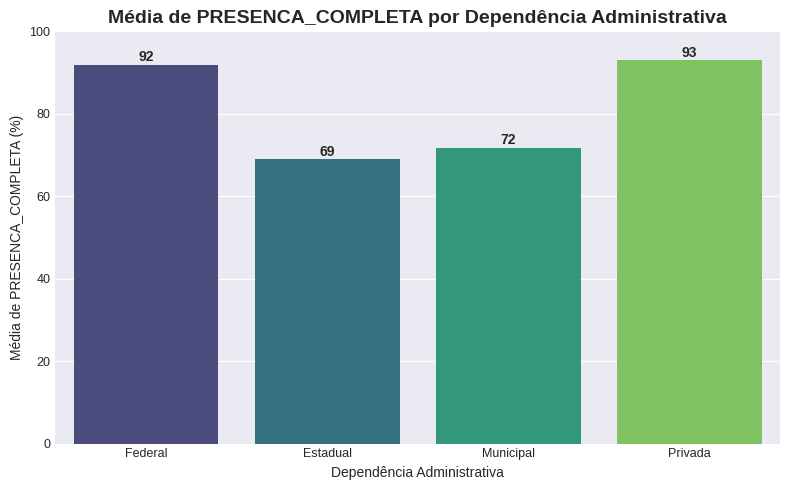

In [ ]:
# mapping dictionary
dependency_map = {
    1: "Federal",
    2: "State",
    3: "Municipal",
    4: "Private"
}

# Compute the mean PRESENCA_COMPLETA per administrative dependency
mean_attendance = data_set.groupby("TP_DEPENDENCIA")["PRESENCA_COMPLETA"].mean().reset_index()
mean_attendance["TP_DEPENDENCIA"] = mean_attendance["TP_DEPENDENCIA"].map(dependency_map)

# If PRESENCA_COMPLETA is between 0 and 1, convert it to a percentage
mean_attendance["PRESENCA_COMPLETA"] = (mean_attendance["PRESENCA_COMPLETA"] * 100).round(2)

# Bar chart
plt.figure(figsize=(8,5))
ax = sns.barplot(
    x="TP_DEPENDENCIA",
    y="PRESENCA_COMPLETA",
    data=mean_attendance,
    palette="viridis"
)
plt.title("Mean PRESENCA_COMPLETA by Administrative Dependency", fontsize=14, weight='bold')
plt.ylabel("Mean PRESENCA_COMPLETA (%)")
plt.xlabel("Administrative Dependency")
plt.ylim(0, 100)

# Label the bars with integer values
for p in ax.patches:
    height = int(round(p.get_height()))
    ax.annotate(f'{height}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Final column names
output_columns = [
    "in_variable",
    "count",
    "PRESENCA_COMPLETA"
]

# Select IN_ columns
cols_in = [c for c in data_set.columns if c.startswith("IN_")]

rows = []

for col in cols_in:
    means = data_set.groupby(col)["PRESENCA_COMPLETA"].mean()
    if 0 in means.index and 1 in means.index:
        impact = means.loc[1] - means.loc[0]  # difference in attendance
        count = data_set[col].sum()         # schools with col == 1

        rows.append([
            col,
            count,
            impact * 100                       # convert to percentage
        ])

# Build the final table
impact_table_simplified = pd.DataFrame(rows, columns=output_columns).round(2)

display(impact_table_simplified)


,variavel_in,contagem,PRESENCA_COMPLETA
0,IN_PREDIO_COMPARTILHADO,1129.0,-5.94
1,IN_AREA_VERDE,10209.0,2.32
2,IN_AUDITORIO,8733.0,8.68
3,IN_BANHEIRO,25012.0,13.78
4,IN_BIBLIOTECA,18120.0,7.18
5,IN_DORMITORIO_ALUNO,501.0,7.99
6,IN_DORMITORIO_PROFESSOR,312.0,8.29
7,IN_LABORATORIO_CIENCIAS,13734.0,8.21
8,IN_LABORATORIO_INFORMATICA,18240.0,-0.73
9,IN_PATIO_COBERTO,17418.0,4.98


In [ ]:
# Filter the table to show only variables with impact greater than 5 or less than -5
impact_table_filtered = impact_table_simplified[
    (impact_table_simplified["PRESENCA_COMPLETA"] > 5) |
    (impact_table_simplified["PRESENCA_COMPLETA"] < -5)
]

# Show the filtered table
print("Variables with impact on PRESENCA_COMPLETA greater than 5% or less than -5%")
display(impact_table_filtered)

Variáveis com impacto na PRESENCA_COMPLETA maior que 5% ou menor que -5%


,variavel_in,contagem,PRESENCA_COMPLETA
0,IN_PREDIO_COMPARTILHADO,1129.0,-5.94
2,IN_AUDITORIO,8733.0,8.68
3,IN_BANHEIRO,25012.0,13.78
4,IN_BIBLIOTECA,18120.0,7.18
5,IN_DORMITORIO_ALUNO,501.0,7.99
6,IN_DORMITORIO_PROFESSOR,312.0,8.29
7,IN_LABORATORIO_CIENCIAS,13734.0,8.21
11,IN_PISCINA,1543.0,16.14
12,IN_QUADRA_ESPORTES,20345.0,5.13
14,IN_SALA_ATELIE_ARTES,3006.0,9.69


In [ ]:
# mapping dictionary
dependency_map = {
    1: "Federal",
    2: "State",
    3: "Municipal",
    4: "Private"
}

# Final column names
output_columns = [
    "TP_DEPENDENCIA",
    "in_variable",
    "count",
    "PRESENCA_COMPLETA"
]

# Select IN_ columns
cols_in = [c for c in data_set.columns if c.startswith("IN_")]

rows = []

# Group by administrative dependency
for dep, df_dep in data_set.groupby("TP_DEPENDENCIA"):
    for col in cols_in:
        means = df_dep.groupby(col)["PRESENCA_COMPLETA"].mean()
        if 0 in means.index and 1 in means.index:
            impact = means.loc[1] - means.loc[0]  # difference in attendance
            count = df_dep[col].sum()           # schools with col == 1

            rows.append([
                dep,
                col,
                count,
                impact * 100                        # convert to percentage
            ])

# Build the final table
impact_table_simplified = pd.DataFrame(rows, columns=output_columns).round(2)

# Replace the codes with readable dependency names
impact_table_simplified["TP_DEPENDENCIA"] = impact_table_simplified["TP_DEPENDENCIA"].map(dependency_map)

# Sort by PRESENCA_COMPLETA descending
impact_table_simplified = impact_table_simplified.sort_values(
    by="PRESENCA_COMPLETA", ascending=False
).reset_index(drop=True)

display(impact_table_simplified)


,TP_DEPENDENCIA,variavel_in,contagem,PRESENCA_COMPLETA
0,Privada,IN_DIURNO,6682.0,42.70
1,Municipal,IN_EXAME_SELECAO,36.0,20.78
2,Estadual,IN_DIURNO,17274.0,19.95
3,Municipal,IN_DIURNO,96.0,18.39
4,Municipal,IN_PROF_SAUDE,2.0,16.90
...,...,...,...,...
247,Municipal,IN_EJA,25.0,-13.06
248,Privada,IN_EJA,231.0,-21.02
249,Municipal,IN_SALA_PROFESSOR,104.0,-21.78
250,Privada,IN_EAD,178.0,-22.26


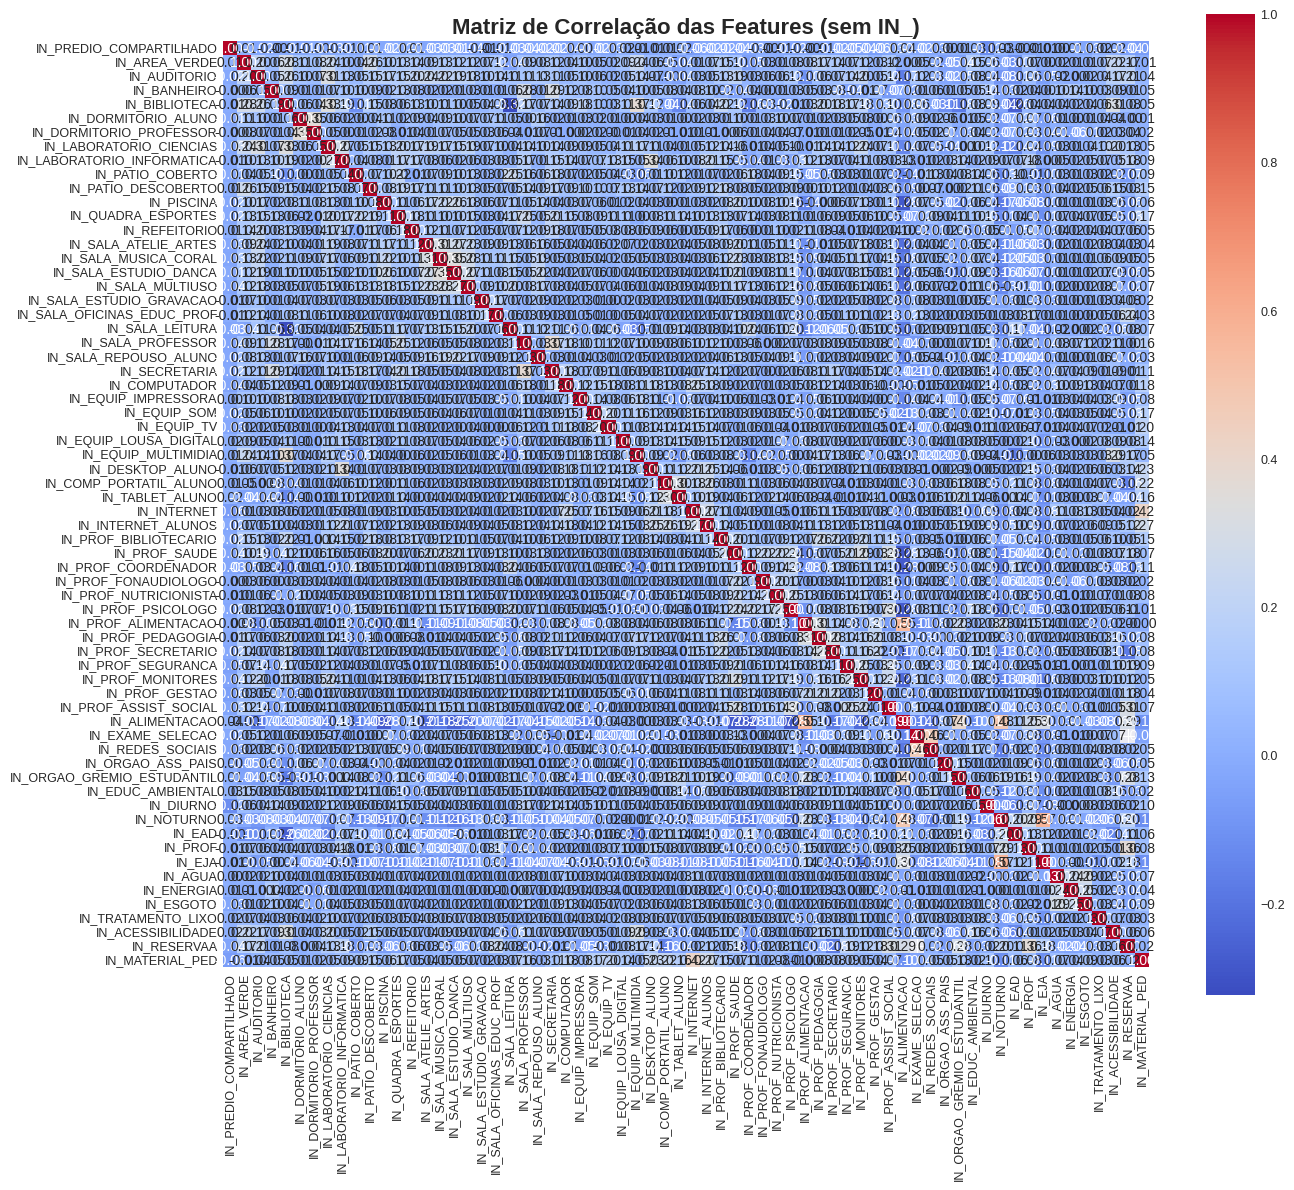

In [ ]:
features_corr = [f for f in all_features if f in features_in]

# Compute the correlation matrix for the selected columns only
corr_matrix = data_set[features_corr].corr()

# Plot the correlation matrix
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True
)
plt.title("Feature Correlation Matrix (without IN_)", fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Filter the correlation matrix to show only absolute values greater than 0.3
corr_matrix_filtered = corr_matrix[abs(corr_matrix) > 0.3]

# Remove the diagonal (correlation of 1 with itself)
np.fill_diagonal(corr_matrix_filtered.values, np.nan)

# Show the filtered matrix
print("Correlation Matrix (absolute values > 0.3):")
display(corr_matrix_filtered)

Matriz de Correlação (valores absolutos > 0.3):


,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PATIO_COBERTO,IN_PATIO_DESCOBERTO,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_ATELIE_ARTES,IN_SALA_MUSICA_CORAL,IN_SALA_ESTUDIO_DANCA,IN_SALA_MULTIUSO,IN_SALA_ESTUDIO_GRAVACAO,IN_SALA_OFICINAS_EDUC_PROF,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,IN_SECRETARIA,IN_COMPUTADOR,IN_EQUIP_IMPRESSORA,IN_EQUIP_SOM,IN_EQUIP_TV,IN_EQUIP_LOUSA_DIGITAL,IN_EQUIP_MULTIMIDIA,IN_DESKTOP_ALUNO,IN_COMP_PORTATIL_ALUNO,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_ALIMENTACAO,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,IN_EJA,IN_AGUA,IN_ENERGIA,IN_ESGOTO,IN_TRATAMENTO_LIXO,IN_ACESSIBILIDADE,IN_RESERVAA,IN_MATERIAL_PED
IN_PREDIO_COMPARTILHADO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_AREA_VERDE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_AUDITORIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.314638,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_BANHEIRO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_BIBLIOTECA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.331064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.322786,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.366321,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.30595,NaN,NaN
IN_DORMITORIO_ALUNO,NaN,NaN,NaN,NaN,NaN,NaN,0.354242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_DORMITORIO_PROFESSOR,NaN,NaN,NaN,NaN,NaN,0.354242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_LABORATORIO_CIENCIAS,NaN,NaN,0.314638,NaN,0.331064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_LABORATORIO_INFORMATICA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.340568,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IN_PATIO_COBERTO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

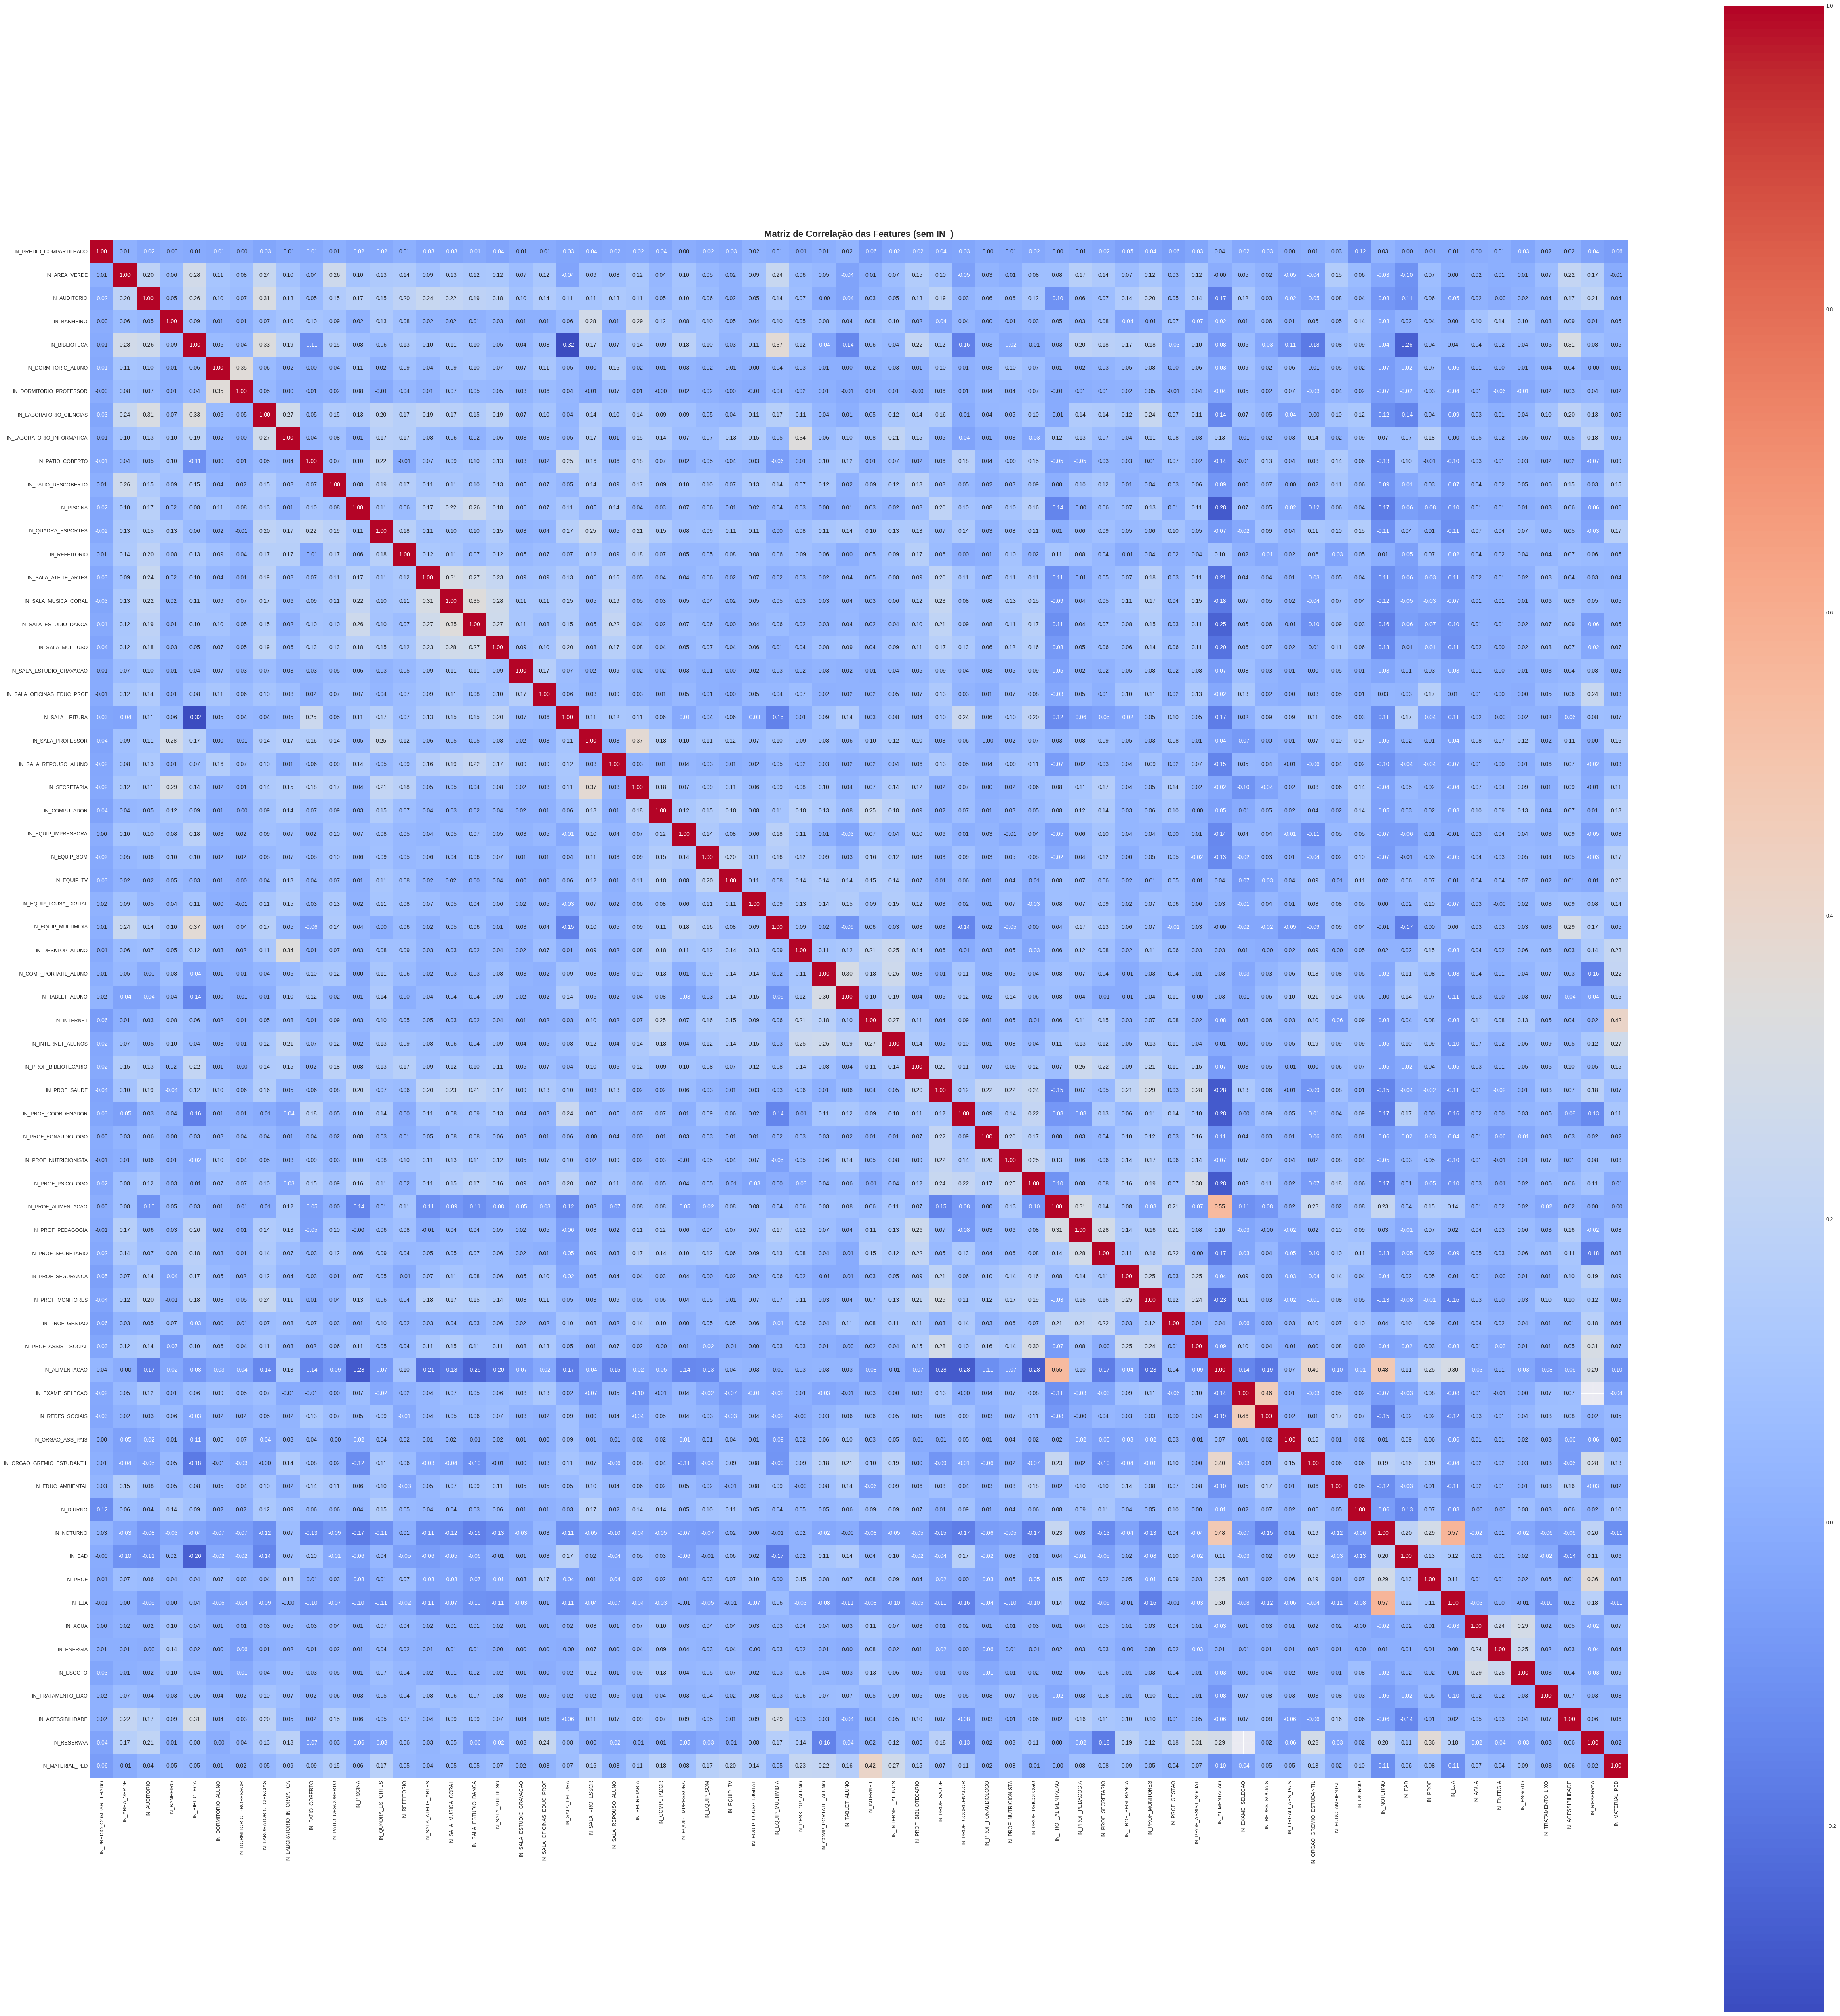

In [ ]:
features_in = [col for col in data_set.columns if col.startswith("IN_")]
features_qt = [col for col in data_set.columns if col.startswith("QT_")]
new_features = [
    "MAT_MED_POR_TURMA",
    "MAT_MED_POR_SALA",
    "PROP_SALAS_CLIMATIZADAS",
    "DOC_MED_POR_TURMA_MED",
    "MAT_MED_POR_DOC_MED"
]

all_features = features_in + features_qt + new_features

features_corr = [f for f in all_features if f in features_in]

# Compute the correlation matrix for the selected columns only
corr_matrix = data_set[features_corr].corr()

# Plot the correlation matrix
plt.figure(figsize=(50, 50))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True
)
plt.title("Feature Correlation Matrix (without IN_)", fontsize=16, weight='bold')
plt.tight_layout()
plt.show()